In [1]:
import pandas
import numpy
import matplotlib
import seaborn
import sklearn

print("All required libraries are installed!")

All required libraries are installed!


In [2]:
print("Credit Card Fraud Detection and Prevention System")

Credit Card Fraud Detection and Prevention System


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score

In [4]:
df=pd.read_csv("C:\ML application\creditcard.csv")
print(df)

<>:1: SyntaxWarning: invalid escape sequence '\M'
<>:1: SyntaxWarning: invalid escape sequence '\M'
C:\Users\User\AppData\Local\Temp\ipykernel_18140\1357059749.py:1: SyntaxWarning: invalid escape sequence '\M'
  df=pd.read_csv("C:\ML application\creditcard.csv")


            Time         V1         V2        V3        V4        V5  \
0            0.0  -1.359807  -0.072781  2.536347  1.378155 -0.338321   
1            0.0   1.191857   0.266151  0.166480  0.448154  0.060018   
2            1.0  -1.358354  -1.340163  1.773209  0.379780 -0.503198   
3            1.0  -0.966272  -0.185226  1.792993 -0.863291 -0.010309   
4            2.0  -1.158233   0.877737  1.548718  0.403034 -0.407193   
...          ...        ...        ...       ...       ...       ...   
284802  172786.0 -11.881118  10.071785 -9.834783 -2.066656 -5.364473   
284803  172787.0  -0.732789  -0.055080  2.035030 -0.738589  0.868229   
284804  172788.0   1.919565  -0.301254 -3.249640 -0.557828  2.630515   
284805  172788.0  -0.240440   0.530483  0.702510  0.689799 -0.377961   
284806  172792.0  -0.533413  -0.189733  0.703337 -0.506271 -0.012546   

              V6        V7        V8        V9  ...       V21       V22  \
0       0.462388  0.239599  0.098698  0.363787  ... -0.01830

In [5]:
df.head(6474)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6469,7734.0,1.123932,0.262310,0.859413,1.324326,-0.374702,-0.130466,-0.342963,0.151904,1.300572,...,-0.358481,-0.885373,0.227291,0.054131,0.069762,-0.709952,0.003945,0.010806,0.93,0
6470,7738.0,1.028722,0.282535,1.753017,2.797754,-0.576534,0.870242,-0.821850,0.352080,1.109368,...,-0.143571,-0.010268,0.098737,0.153542,0.146209,-0.082189,0.029619,0.017801,0.00,0
6471,7739.0,-2.608460,-0.980463,2.577244,-0.253370,2.858780,-0.949880,1.194871,-2.043584,2.885661,...,-0.838785,0.084507,-1.529359,0.308810,0.113584,0.164855,-1.808663,-1.447678,29.99,0
6472,7740.0,1.023874,2.001485,-4.769752,3.819195,-1.271754,-1.734662,-3.059245,0.889805,0.415382,...,0.343283,-0.054196,0.709654,-0.372216,-2.032068,0.366778,0.395171,0.020206,1.00,1


In [6]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 284807
Number of columns: 31


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [8]:
df['Class'].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

In [9]:
df['Class'].value_counts(normalize=True) * 100

Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64

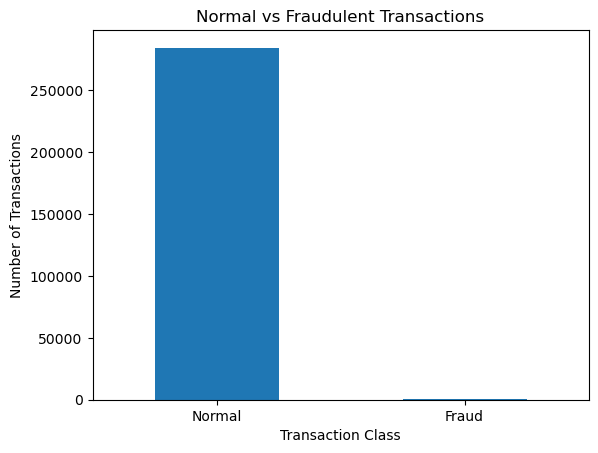

In [10]:
df['Class'].value_counts().plot(kind='bar')

plt.title("Normal vs Fraudulent Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Normal", "Fraud"], rotation=0)

plt.show()

In [11]:
X = df.drop('Class', axis=1)
y = df['Class']

print("Input shape:", X.shape)
print("Output shape:", y.shape)

Input shape: (284807, 30)
Output shape: (284807,)


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (227845, 30)
Testing data: (56962, 30)


In [13]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced'
)

print("Random Forest model created successfully!")

Random Forest model created successfully!


In [14]:
rf_model.fit(X_train, y_train)
print("Model trained successfully!")

Model trained successfully!


In [15]:
rf_pred = rf_model.predict(X_test)

print("Predictions completed successfully!")

Predictions completed successfully!


In [16]:
accuracy = accuracy_score(y_test, rf_pred)

print("Model Accuracy:", accuracy)
print("Model Accuracy (%):", accuracy * 100)

Model Accuracy: 0.9995084442259752
Model Accuracy (%): 99.95084442259751


In [17]:
print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.96      0.74      0.84        98

    accuracy                           1.00     56962
   macro avg       0.98      0.87      0.92     56962
weighted avg       1.00      1.00      1.00     56962



In [18]:
cm = confusion_matrix(y_test, rf_pred)

print(cm)

[[56861     3]
 [   25    73]]


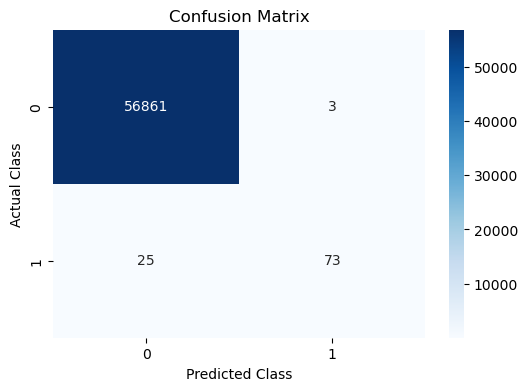

In [19]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()

In [20]:
sample_transaction = X_test.iloc[[0]]

print("Sample transaction:")
display(sample_transaction)

Sample transaction:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
263020,160760.0,-0.674466,1.408105,-1.110622,-1.328366,1.388996,-1.308439,1.885879,-0.614233,0.311652,...,0.394322,0.080084,0.810034,-0.224327,0.707899,-0.135837,0.045102,0.533837,0.291319,23.0


In [21]:
prediction = rf_model.predict(sample_transaction)

if prediction[0] == 1:
    print("🚨 FRAUDULENT TRANSACTION DETECTED")
else:
    print("✅ NORMAL TRANSACTION")

✅ NORMAL TRANSACTION


In [22]:
probability = rf_model.predict_proba(sample_transaction)

fraud_probability = probability[0][1]

print("Fraud Probability:", fraud_probability)
print("Fraud Probability (%):", fraud_probability * 100)

Fraud Probability: 0.0
Fraud Probability (%): 0.0


In [23]:
if fraud_probability >= 0.80:
    print("🚨 HIGH RISK")
    print("Action: Block transaction and perform verification.")

elif fraud_probability >= 0.50:
    print("⚠️ MEDIUM RISK")
    print("Action: Request additional verification.")

else:
    print("✅ LOW RISK")
    print("Action: Allow transaction.")

✅ LOW RISK
Action: Allow transaction.


In [24]:
feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

feature_importance.head(10)

V14    0.179857
V10    0.115442
V12    0.096206
V4     0.095646
V17    0.095113
V3     0.068669
V11    0.056112
V16    0.040303
V2     0.036265
V9     0.026888
dtype: float64

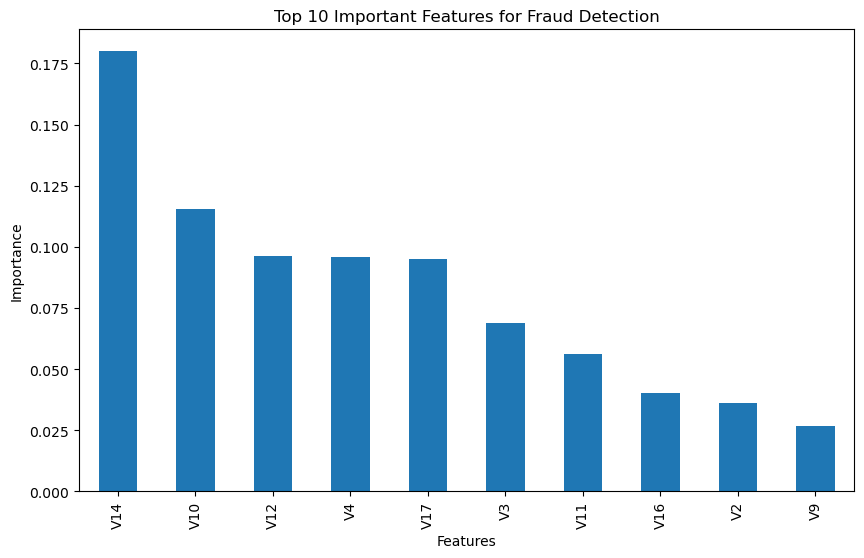

In [25]:
plt.figure(figsize=(10, 6))

feature_importance.head(10).plot(kind='bar')

plt.title("Top 10 Important Features for Fraud Detection")
plt.xlabel("Features")
plt.ylabel("Importance")

plt.show()

In [26]:
print("==============================================")
print("   CREDIT CARD FRAUD DETECTION SYSTEM")
print("==============================================")

print("\nModel Used: Random Forest Classifier")
print("Accuracy:", accuracy * 100, "%")
print("Fraud Probability:", fraud_probability * 100, "%")

if fraud_probability >= 0.80:
    print("\nRisk Level: HIGH")
    print("Decision: BLOCK / VERIFY TRANSACTION")

elif fraud_probability >= 0.50:
    print("\nRisk Level: MEDIUM")
    print("Decision: ADDITIONAL VERIFICATION REQUIRED")

else:
    print("\nRisk Level: LOW")
    print("Decision: TRANSACTION ALLOWED")

print("==============================================")

   CREDIT CARD FRAUD DETECTION SYSTEM

Model Used: Random Forest Classifier
Accuracy: 99.95084442259751 %
Fraud Probability: 0.0 %

Risk Level: LOW
Decision: TRANSACTION ALLOWED
